# Comprobación de corridas, artefactos y selección del modelo de P3 en MLflow — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P3 (agrupamiento de estaciones) · Semana 6  
**Autor:** Joel Sánchez (`PittJR1607`) · **Rama:** `feature/p3-mlflow-experiments`  
**Antecedentes:** `3.0-js-p3-exploracion-estaciones.ipynb`, `3.1-js-p3-agrupamiento.ipynb` y `equipo52_module/modeling/train_p3.py`.

**Propósito.** Comprobar que las corridas oficiales de P3 lanzadas con `mlflow run` coincidan exactamente con las cifras de referencia del notebook `3.1`, verificar que cada corrida candidata cuente con las etiquetas obligatorias (`question`, `model_family`, `stage_of_work`), los artefactos organizados en `plots/`, `data/` y `config/`, el registro de conjuntos con `mlflow.log_input` y el modelo con firma, analizar la búsqueda con *nested runs* y documentar la decisión de selección entre el modelo `champion` (`p3-kmeans-k4`) y el `challenger` (`p3-kmeans-k2`) registrada en `mibici-equipo52-p3-grupos`.

In [1]:
# Objetivo: conectarse al servidor de MLflow y consultar las corridas oficiales de P3 (fuente PROJECT).
# Resultado esperado: baseline, búsqueda con nested runs y candidatas terminadas en mibici-equipo52.

import json
from pathlib import Path
import sys

from IPython.display import Image, display
import matplotlib.pyplot as plt
import mlflow
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from equipo52_module.config import MLFLOW_EXPERIMENT, MLFLOW_TRACKING_URI, PROJ_ROOT

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
cliente = mlflow.MlflowClient()
experimento = cliente.get_experiment_by_name(MLFLOW_EXPERIMENT)
corridas = mlflow.search_runs(
    [experimento.experiment_id],
    filter_string="tags.question = 'p3' and attributes.status = 'FINISHED'",
    order_by=["attributes.start_time DESC"],
)
oficiales = corridas[corridas["tags.mlflow.source.type"] == "PROJECT"].copy()
print(f"Servidor: {MLFLOW_TRACKING_URI} · Experimento: {experimento.name} (id={experimento.experiment_id})")
print(f"Corridas totales de P3 (incluyendo hijas nested): {len(corridas)} · Corridas raíz PROJECT: {len(oficiales)}")
oficiales[["tags.mlflow.runName", "tags.stage_of_work", "tags.model_family", "tags.commit", "start_time"]]

/Users/pittjr/JSO_DEV/ITESM/MAESTRIA_IA/3rdTrim/TC5061-Proyecto-Equipo52/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-25 20:18:19.664 | INFO     | equipo52_module.config:<module>:12 - PROJ_ROOT path is: /Users/pittjr/JSO_DEV/ITESM/MAESTRIA_IA/3rdTrim/TC5061-Proyecto-Equipo52


Servidor: http://127.0.0.1:5000 · Experimento: mibici-equipo52 (id=1)
Corridas totales de P3 (incluyendo hijas nested): 18 · Corridas raíz PROJECT: 8


,tags.mlflow.runName,tags.stage_of_work,tags.model_family,tags.commit,start_time
0,p3-ward-k2,candidate,ward,d31f904e4c7ba6edd7059af7cc25bf4e74c47e45,2026-10-26 01:45:55.349000+00:00
1,p3-hdbscan-mcs15,candidate,hdbscan,d31f904e4c7ba6edd7059af7cc25bf4e74c47e45,2026-10-26 01:45:03.334000+00:00
2,p3-ward-k4,candidate,ward,d31f904e4c7ba6edd7059af7cc25bf4e74c47e45,2026-10-26 01:44:31.360000+00:00
3,p3-kmeans-k4-consolidadas,candidate,kmeans,d31f904e4c7ba6edd7059af7cc25bf4e74c47e45,2026-10-26 01:44:00.507000+00:00
4,p3-kmeans-k2,candidate,kmeans,d31f904e4c7ba6edd7059af7cc25bf4e74c47e45,2026-10-26 01:43:28.025000+00:00
5,p3-kmeans-k4,candidate,kmeans,d31f904e4c7ba6edd7059af7cc25bf4e74c47e45,2026-10-26 01:42:54.241000+00:00
16,p3-busqueda-kmeans,search,kmeans,d31f904e4c7ba6edd7059af7cc25bf4e74c47e45,2026-10-26 01:40:38.514000+00:00
17,p3-geo-k5,baseline,baseline,d31f904e4c7ba6edd7059af7cc25bf4e74c47e45,2026-10-26 01:39:02.140000+00:00


## 1. Comprobación contra las cifras de referencia del notebook 3.1

Verificamos que las corridas oficiales lanzadas desde el `MLproject` (`p3-geo-k5`, `p3-kmeans-k4` y `p3-kmeans-k2`) reproduzcan exactamente las estaciones, características y métricas internas y de estabilidad calculadas en el notebook `3.1-js-p3-agrupamiento.ipynb`.

In [2]:
# Objetivo: contrastar parámetros y métricas de las corridas oficiales contra el notebook 3.1.
# Resultado esperado: todas las filas con 'Coincide ✅'.

REFERENCIA_31 = [
    ("p3-geo-k5", "parámetro", "n_estaciones", 469),
    ("p3-geo-k5", "parámetro", "n_caracteristicas", 42),
    ("p3-geo-k5", "métrica", "hist_silhouette", 0.019),
    ("p3-geo-k5", "métrica", "hist_davies_bouldin", 3.267),
    ("p3-kmeans-k2", "métrica", "hist_silhouette", 0.151),
    ("p3-kmeans-k2", "métrica", "estabilidad_eras_ari", 0.618),
    ("p3-kmeans-k2", "métrica", "estabilidad_bootstrap_ari", 0.952),
    ("p3-kmeans-k4", "métrica", "hist_silhouette", 0.105),
    ("p3-kmeans-k4", "métrica", "hist_davies_bouldin", 2.309),
    ("p3-kmeans-k4", "métrica", "estabilidad_eras_ari", 0.571),
    ("p3-kmeans-k4", "métrica", "estabilidad_bootstrap_ari", 0.841),
]

filas_comp = []
for nombre_run, tipo, clave, ref in REFERENCIA_31:
    fila = oficiales[oficiales["tags.mlflow.runName"] == nombre_run].iloc[0]
    col = f"params.{clave}" if tipo == "parámetro" else f"metrics.{clave}"
    reg = float(fila[col])
    ok = int(reg) == ref if tipo == "parámetro" else round(reg, 3) == ref
    filas_comp.append({
        "corrida": nombre_run, "tipo": tipo, "nombre": clave,
        "referencia 3.1": ref, "corrida oficial": round(reg, 3) if tipo == "métrica" else int(reg),
        "resultado": "Coincide ✅" if ok else "NO coincide ❌"
    })
df_comp = pd.DataFrame(filas_comp)
display(df_comp)
assert (df_comp["resultado"] == "Coincide ✅").all()

,corrida,tipo,nombre,referencia 3.1,corrida oficial,resultado
0,p3-geo-k5,parámetro,n_estaciones,469.000,469.000,Coincide ✅
1,p3-geo-k5,parámetro,n_caracteristicas,42.000,42.000,Coincide ✅
2,p3-geo-k5,métrica,hist_silhouette,0.019,0.019,Coincide ✅
3,p3-geo-k5,métrica,hist_davies_bouldin,3.267,3.267,Coincide ✅
4,p3-kmeans-k2,métrica,hist_silhouette,0.151,0.151,Coincide ✅
5,p3-kmeans-k2,métrica,estabilidad_eras_ari,0.618,0.618,Coincide ✅
6,p3-kmeans-k2,métrica,estabilidad_bootstrap_ari,0.952,0.952,Coincide ✅
7,p3-kmeans-k4,métrica,hist_silhouette,0.105,0.105,Coincide ✅
8,p3-kmeans-k4,métrica,hist_davies_bouldin,2.309,2.309,Coincide ✅
9,p3-kmeans-k4,métrica,estabilidad_eras_ari,0.571,0.571,Coincide ✅


## 2. Búsqueda de hiperparámetros con *nested runs* (`p3-busqueda-kmeans`)

Inspeccionamos la corrida padre `p3-busqueda-kmeans` y sus 10 corridas hijas (`k` de 2 a 6 × `solo_consolidadas` `False`/`True`), junto con el artefacto gráfico `plots/p3_busqueda_silueta.png`.

Corrida padre: p3-busqueda-kmeans (ca6440092f7049d3a02ffa2d246510d5) · mejor global: {"k": 2, "solo_consolidadas": true} · óptimo operativo: {"k": 4, "solo_consolidadas": false}


,k,solo_consolidadas,val_silhouette,val_davies_bouldin,val_calinski_harabasz,hist_silhouette,hist_davies_bouldin,hist_calinski_harabasz,estabilidad_eras_ari,estabilidad_bootstrap_ari,segundos_entrenamiento
0,2,True,0.154,2.204,64.302,0.147,2.241,77.685,0.546,0.944,9.93
1,2,False,0.145,2.234,56.336,0.151,2.309,75.182,0.618,0.952,9.16
2,4,False,0.131,2.075,41.626,0.105,2.309,50.586,0.571,0.841,9.94
3,4,True,0.127,2.102,45.052,0.075,2.392,49.263,0.436,0.846,9.61
4,3,False,0.119,2.314,47.018,0.092,2.349,56.030,0.519,0.727,10.24
5,5,True,0.117,2.029,41.263,0.057,2.320,43.240,0.467,0.831,9.89
6,3,True,0.115,2.277,50.015,0.066,2.418,51.016,0.444,0.850,10.31
7,6,True,0.109,2.170,36.993,0.047,2.310,39.961,0.425,0.617,10.18
8,6,False,0.099,2.206,32.087,0.065,2.330,39.254,0.415,0.690,9.80
9,5,False,0.098,2.163,38.103,0.064,2.330,43.643,0.488,0.812,9.28


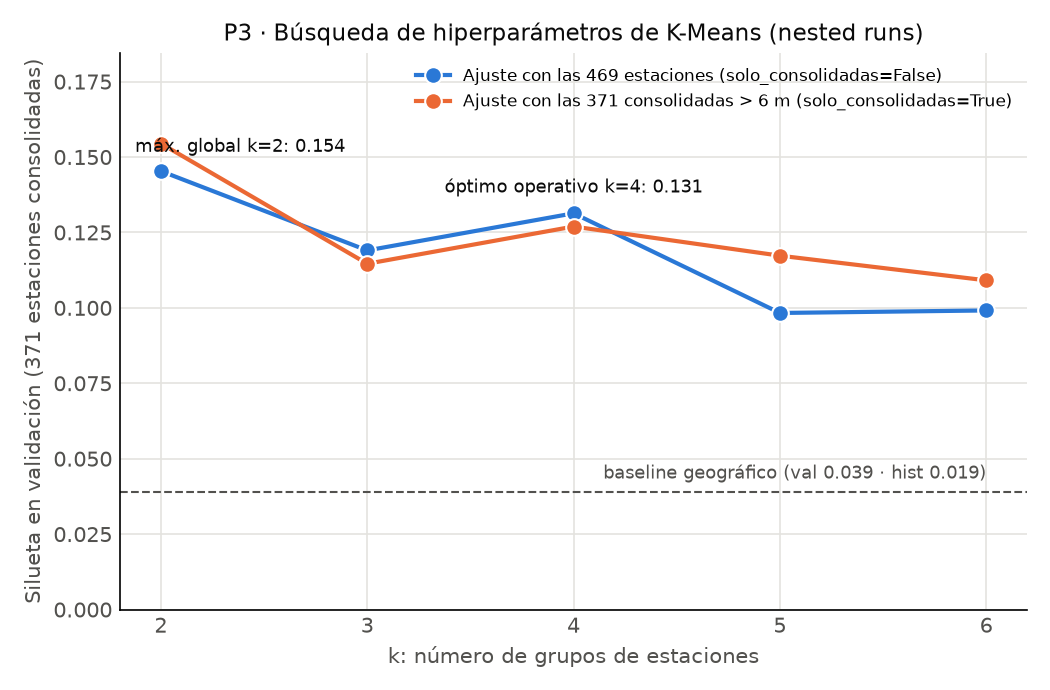

In [3]:
# Objetivo: descargar la tabla y la gráfica de resultados de la corrida padre de búsqueda.
# Resultado esperado: tabla de las 10 combinaciones ordenadas por val_silhouette y curva comparativa.

padre = oficiales[oficiales["tags.stage_of_work"] == "search"].iloc[0]
resultados_busqueda = pd.read_csv(
    mlflow.artifacts.download_artifacts(run_id=padre["run_id"], artifact_path="data/p3_busqueda_resultados.csv")
)
print(
    f"Corrida padre: {padre['tags.mlflow.runName']} ({padre['run_id']}) · "
    f"mejor global: {padre['tags.mejor_combinacion']} · "
    f"óptimo operativo: {padre['tags.mejor_combinacion_operativa']}"
)
display(resultados_busqueda.round(3))
display(Image(mlflow.artifacts.download_artifacts(run_id=padre["run_id"], artifact_path="plots/p3_busqueda_silueta.png")))

## 3. Tabla comparativa de candidatas contra el baseline (Tabla 3 del reporte) y costo

Comparamos el baseline (`p3-geo-k5`) y las corridas candidatas en validación (`val_silhouette`, `val_davies_bouldin`), en la red completa (`hist_silhouette`, `hist_davies_bouldin`, `hist_calinski_harabasz`), en estabilidad (`estabilidad_eras_ari`, `estabilidad_bootstrap_ari`) y en costo (`segundos_entrenamiento` y tamaño del modelo en KB).

In [4]:
# Objetivo: construir la tabla comparativa de candidatas frente a p3-geo-k5 incluyendo tamaño del modelo.
# Resultado esperado: tabla ordenada con mejoras en puntos y en porcentaje.

def kilobytes_del_modelo(run_id: str) -> float | None:
    modelos = mlflow.search_logged_models(
        experiment_ids=[experimento.experiment_id],
        filter_string=f"source_run_id = '{run_id}'",
        output_format="list",
    )
    if not modelos:
        return None
    ruta = Path(mlflow.artifacts.download_artifacts(f"models:/{modelos[0].model_id}"))
    return round(sum(f.stat().st_size for f in ruta.rglob("*") if f.is_file()) / 1e3, 1)

ultimas = oficiales[oficiales["tags.stage_of_work"].isin(["baseline", "candidate"])].drop_duplicates("tags.mlflow.runName")
base = ultimas[ultimas["tags.stage_of_work"] == "baseline"].iloc[0]
sil_base_val = float(base["metrics.val_silhouette"])
sil_base_hist = float(base["metrics.hist_silhouette"])

filas_tabla = []
for _, r in ultimas.iterrows():
    sil_h = float(r["metrics.hist_silhouette"])
    filas_tabla.append({
        "corrida": r["tags.mlflow.runName"],
        "etapa": r["tags.stage_of_work"],
        "familia": r["tags.model_family"],
        "k": r.get("params.k_elegido") or r.get("params.k"),
        "solo_consolidadas": r.get("params.solo_consolidadas"),
        "val_silhouette": round(float(r["metrics.val_silhouette"]), 3),
        "val_db": round(float(r["metrics.val_davies_bouldin"]), 3) if pd.notna(r.get("metrics.val_davies_bouldin")) else None,
        "hist_silhouette": round(sil_h, 3),
        "hist_db": round(float(r["metrics.hist_davies_bouldin"]), 3) if pd.notna(r.get("metrics.hist_davies_bouldin")) else None,
        "eras_ari": round(float(r["metrics.estabilidad_eras_ari"]), 3) if pd.notna(r.get("metrics.estabilidad_eras_ari")) else None,
        "bootstrap_ari": round(float(r["metrics.estabilidad_bootstrap_ari"]), 3) if pd.notna(r.get("metrics.estabilidad_bootstrap_ari")) else None,
        "mejora_hist_pts": round(sil_h - sil_base_hist, 3),
        "mejora_hist_%": round((sil_h / sil_base_hist - 1) * 100, 1) if sil_h > 0 else None,
        "segundos": round(float(r["metrics.segundos_entrenamiento"]), 1),
        "modelo_KB": kilobytes_del_modelo(r["run_id"]),
    })
tabla_comp = pd.DataFrame(filas_tabla).sort_values("val_silhouette", ascending=False).reset_index(drop=True)
display(tabla_comp)

,corrida,etapa,familia,k,solo_consolidadas,val_silhouette,val_db,hist_silhouette,hist_db,eras_ari,bootstrap_ari,mejora_hist_pts,mejora_hist_%,segundos,modelo_KB
0,p3-kmeans-k2,candidate,kmeans,2,false,0.145,2.234,0.151,2.309,0.618,0.952,0.132,698.6,10.1,37.6
1,p3-kmeans-k4,candidate,kmeans,4,false,0.131,2.075,0.105,2.309,0.571,0.841,0.086,457.7,10.7,38.2
2,p3-kmeans-k4-consolidadas,candidate,kmeans,4,true,0.127,2.102,0.075,2.391,0.435,0.846,0.056,297.4,10.1,37.8
3,p3-ward-k2,candidate,ward,2,false,0.123,2.506,0.129,2.541,0.648,0.543,0.110,585.1,10.6,33.6
4,p3-ward-k4,candidate,ward,4,false,0.079,2.286,0.044,2.541,0.591,0.455,0.025,133.9,9.7,35.0
5,p3-geo-k5,baseline,baseline,5,false,0.039,2.982,0.019,3.267,1.000,0.915,0.000,0.0,10.9,14.3
6,p3-hdbscan-mcs15,candidate,hdbscan,NaN,false,0.000,NaN,0.000,NaN,NaN,NaN,-0.019,NaN,0.1,NaN


## 4. Verificación de artefactos (`plots/`, `data/`, `config/`), `log_input` y modelo en producción

Comprobamos la estructura de artefactos de la corrida `champion` (`p3-kmeans-k4`) y verificamos la carga desde el Model Registry mediante el alias `models:/mibici-equipo52-p3-grupos@champion`.

In [5]:
# Objetivo: listar los artefactos y datasets de p3-kmeans-k4 y probar la carga de @champion.
# Resultado esperado: subcarpetas config/, data/, plots/, 3 datasets log_input y predicción con el champion.

champ_run = ultimas[ultimas["tags.mlflow.runName"] == "p3-kmeans-k4"].iloc[0]
run_id_champ = champ_run["run_id"]
print(f"Corrida champion: {champ_run['tags.mlflow.runName']} · run_id={run_id_champ}")

def listar_artefactos(ruta=""):
    for archivo in cliente.list_artifacts(run_id_champ, ruta):
        if archivo.is_dir:
            listar_artefactos(archivo.path)
        else:
            print(f"  {archivo.path}  ({archivo.file_size:,} bytes)")

listar_artefactos()

print("\nConjuntos registrados con mlflow.log_input:")
for entrada in cliente.get_run(run_id_champ).inputs.dataset_inputs:
    ctx = [t.value for t in entrada.tags if t.key == "mlflow.data.context"]
    print(f"  {entrada.dataset.name} ({ctx[0]}) · digest={entrada.dataset.digest}")

uri_champion = "models:/mibici-equipo52-p3-grupos@champion"
version_champ = cliente.get_model_version_by_alias("mibici-equipo52-p3-grupos", "champion")
modelo_prod = mlflow.pyfunc.load_model(uri_champion)
pred_ejemplo = modelo_prod.predict(modelo_prod.input_example)
print(f"\nModelo cargado desde {uri_champion} → versión {version_champ.version} (run_id={version_champ.run_id})")
print(f"Predicción para las 5 estaciones del input_example: {[int(x) for x in pred_ejemplo]}")

Corrida champion: p3-kmeans-k4 · run_id=f1721278a8f44272ac05bae27b51fe1b
  config/MLproject  (1,320 bytes)
  config/config.py  (2,807 bytes)
  config/corrida_p3.json  (2,142 bytes)
  config/python_env.yaml  (112 bytes)
  data/manifiesto_datos.csv  (24,108 bytes)
  data/p3_descripcion_grupos_kmeans-k4.csv  (672 bytes)
  data/p3_matriz_kmeans-k4.csv  (354,400 bytes)
  plots/p3_mapa_clusters_kmeans_k4.png  (167,876 bytes)
  plots/p3_perfiles_horarios_k4.png  (127,181 bytes)
  plots/p3_silueta_vs_k.png  (71,331 bytes)

Conjuntos registrados con mlflow.log_input:
  p3-estaciones-ajuste-completo (training) · digest=3c360766
  p3-estaciones-consolidadas-validacion (validation) · digest=68673df6
  p3-estaciones-red-completa (testing) · digest=9d651f12



Modelo cargado desde models:/mibici-equipo52-p3-grupos@champion → versión 1 (run_id=f1721278a8f44272ac05bae27b51fe1b)
Predicción para las 5 estaciones del input_example: [0, 0, 0, 2, 0]
